# A4 —  A Quantum Circuit That Paints

Vivekananda GN

**Generative models** learn to *create* new data. In the drug-discovery study the quantum circuit generated molecule features; here it generates a **picture**.
We train a 6-qubit circuit so that its random measurement outcomes ("photon hits") land on pixels of a smiley face.
Each measurement picks one of 64 pixels (6 qubits = 64 outcomes).

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.7 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)
from scipy.optimize import minimize

[Qibo 0.3.5|INFO|2026-10-03 04:28:06]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


## 1. The target picture (8 × 8 pixels)

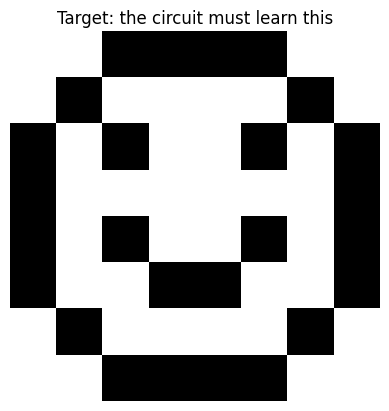

In [ ]:
img = np.array([[0,0,1,1,1,1,0,0],[0,1,0,0,0,0,1,0],[1,0,1,0,0,1,0,1],[1,0,0,0,0,0,0,1],
                [1,0,1,0,0,1,0,1],[1,0,0,1,1,0,0,1],[0,1,0,0,0,0,1,0],[0,0,1,1,1,1,0,0]], float)
target = img.ravel() + 0.02; target /= target.sum()
plt.imshow(img, cmap='gray_r'); plt.title('Target: the circuit must learn this'); plt.axis('off'); plt.show()

## 2. The quantum circuit (a 'Born machine'): its measurement probabilities are the model
Before training, it paints noise.

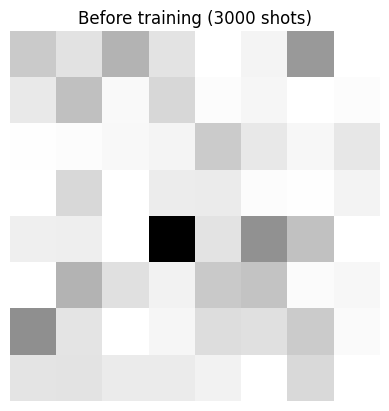

In [ ]:
NQ, L = 6, 8
def circuit_probs(theta):
    th = theta.reshape(L, NQ); c = Circuit(NQ)
    for l in range(L):
        for q in range(NQ): c.add(gates.RY(q, th[l, q]))
        for q in range(NQ): c.add(gates.CNOT(q, (q + 1) % NQ))
    return c().probabilities()

def sample_image(theta, n_shots, seed=0):
    p = circuit_probs(theta); s = np.random.default_rng(seed).choice(64, size=n_shots, p=p / p.sum())
    return np.bincount(s, minlength=64).reshape(8, 8)

theta0 = np.random.default_rng(0).uniform(0, 2*np.pi, L*NQ)
plt.imshow(sample_image(theta0, 3000), cmap='gray_r'); plt.title('Before training (3000 shots)'); plt.axis('off'); plt.show()

## 3. Train (about 30 seconds). The optimiser adjusts 48 rotation angles to make the circuit's output resemble the picture.

In [ ]:
def kl(theta):
    p = np.clip(circuit_probs(theta), 1e-9, 1)
    return np.sum(target * np.log(target / p))

best = None
for seed in range(2):                                    # two random restarts, keep the better
    r = minimize(kl, np.random.default_rng(seed).uniform(0, 2*np.pi, L*NQ), method='L-BFGS-B', options={'maxiter': 400})
    print(f"restart {seed}: final mismatch (KL) = {r.fun:.3f}")
    if best is None or r.fun < best.fun: best = r
theta = best.x

restart 0: final mismatch (KL) = 0.014
restart 1: final mismatch (KL) = 0.020


## 4. watch the picture emerge, one measurement at a time

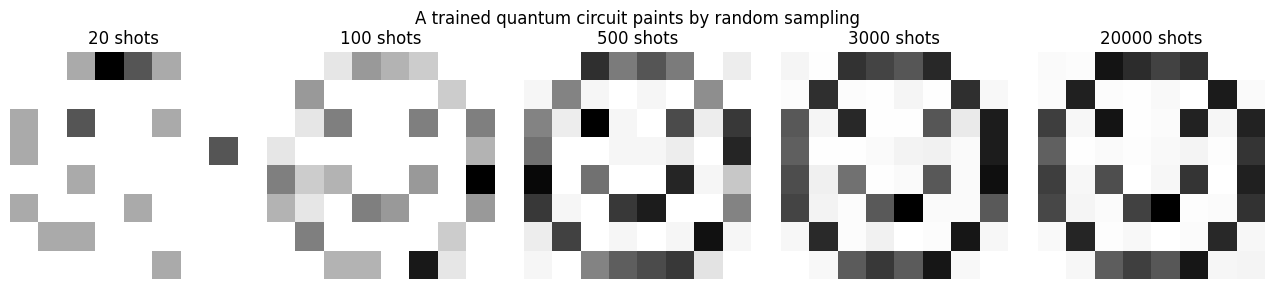

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(13, 2.9))
for a, n in zip(ax, [20, 100, 500, 3000, 20000]):
    a.imshow(sample_image(theta, n, seed=n), cmap='gray_r'); a.set_title(f'{n} shots'); a.axis('off')
plt.suptitle('A trained quantum circuit paints by random sampling'); plt.tight_layout(); plt.show()

## 5. Discussion
* This is the same idea as the drug-discovery generator: learn a probability distribution, then **sample new items** from it.
* we are using a classical computer to *simulate* the circuit. 6 qubits are easy to simulate; the research question is whether larger circuits can generate data that classical models cannot.
* **Try:** change `L` to 2 and 12. Which gives the best picture? Draw your own 8×8 pattern (letters, an arrow, your initials) in `img`.
* **Challenge:** use 4 qubits (4×4 image).